<a href="https://colab.research.google.com/github/MadeOka06/PCVK_Ganjil_2026/blob/main/Praktikum10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1.Persiapan dan Import Library

In [6]:
# Import library yang dibutuhkan
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

# Akses drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#2. Enam Metode Template Matching (Kucing & Kelinci)

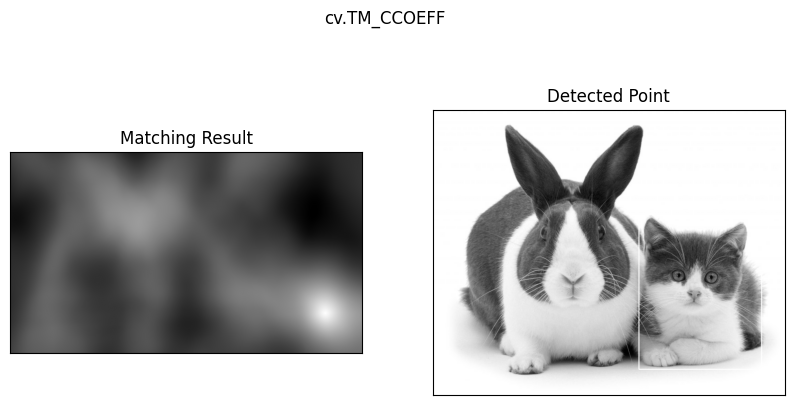

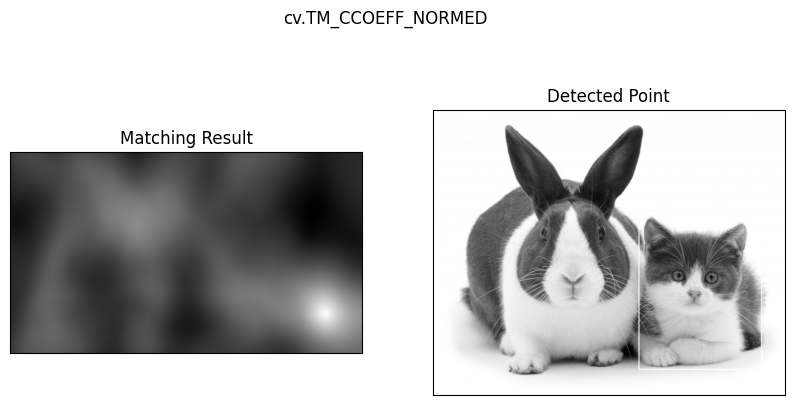

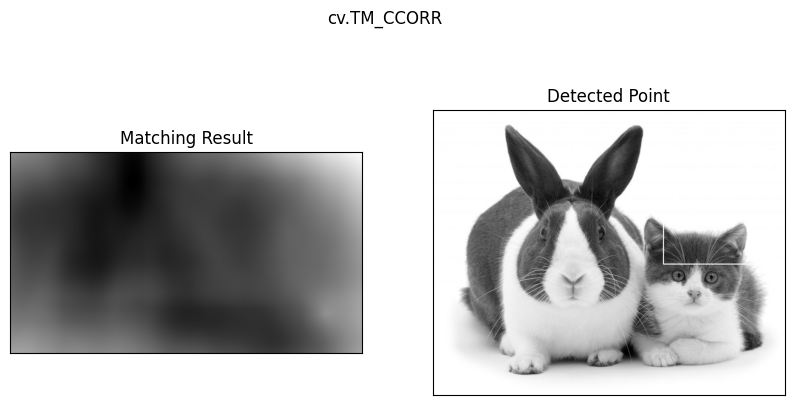

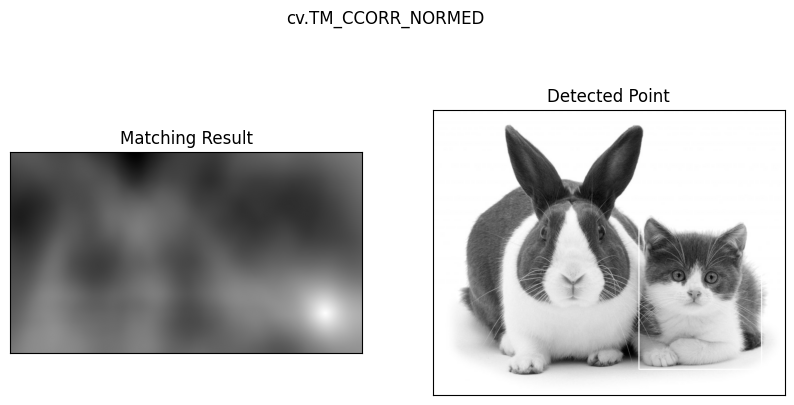

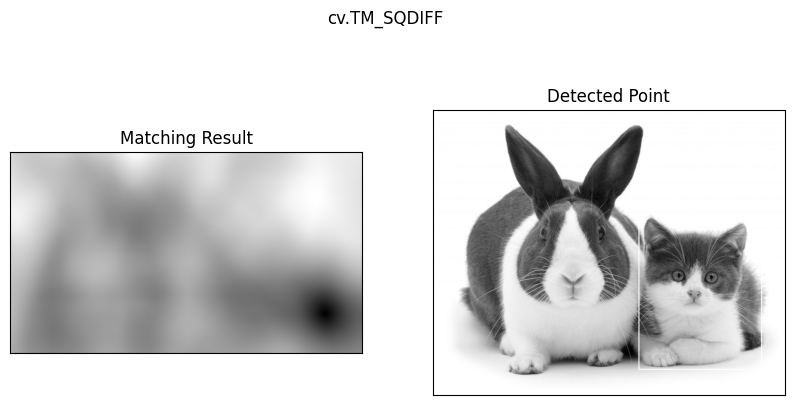

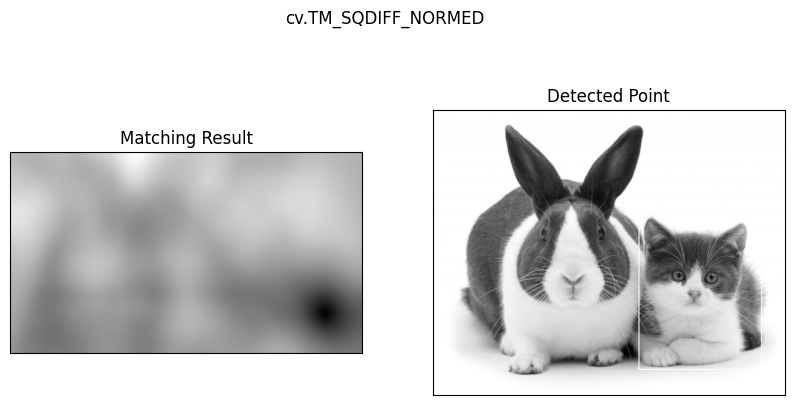

In [14]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/cats_and_bunnies.jpg',0)
img2 = img.copy()
template = cv.imread('/content/drive/MyDrive/PCVK/Images/cat2_templatejpg.jpg',0)
w, h = template.shape[::-1]

# 6 Metode Template Matching di OpenCV
methods = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED', 'cv.TM_CCORR',
            'cv.TM_CCORR_NORMED', 'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

for meth in methods:
    img = img2.copy()
    method = eval(meth)

    # Menerapkan template Matching
    res = cv.matchTemplate(img, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    # Jika menggunakan TM_SQDIFF atau TM_SQDIFF_NORMED, ambil nilai minimum
    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc
    bottom_right = (top_left[0] + w, top_left[1] + h)

    cv.rectangle(img, top_left, bottom_right, 255, 2)

    plt.figure(figsize=(10,5))
    plt.subplot(121), plt.imshow(res, cmap='gray')
    plt.title('Matching Result'), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(img, cmap='gray')
    plt.title('Detected Point'), plt.xticks([]), plt.yticks([])
    plt.suptitle(meth)
    plt.show()

#3. Template Matching Multiple Object (Bahrain)

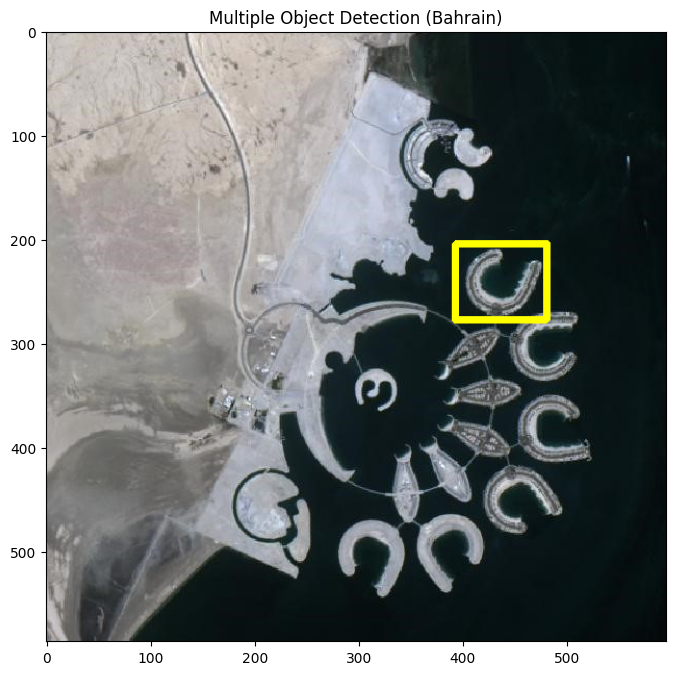

In [16]:
img_rgb = cv.imread('/content/drive/MyDrive/PCVK/Images/bahrain.jpg')
img_gray = cv.cvtColor(img_rgb, cv.COLOR_BGR2GRAY)
template = cv.imread('/content/drive/MyDrive/PCVK/Images/bahrain-template.jpg',0)
w, h = template.shape[::-1]

res = cv.matchTemplate(img_gray, template, cv.TM_CCOEFF_NORMED)
threshold = 0.8 # Nilai threshold untuk multiple obyek
loc = np.where(res >= threshold)

for pt in zip(*loc[::-1]):
    cv.rectangle(img_rgb, pt, (pt[0] + w, pt[1] + h), (0,255,255), 2)

plt.figure(figsize=(8,8))
plt.imshow(cv.cvtColor(img_rgb, cv.COLOR_BGR2RGB))
plt.title('Multiple Object Detection (Bahrain)')
plt.show()

#4. Edge Detection (Sobel, Canny, Laplacian)

/usr/local/lib/python3.13/dist-packages/matplotlib/colors.py:2293: RuntimeWarning: invalid value encountered in subtract
  resdat -= vmin


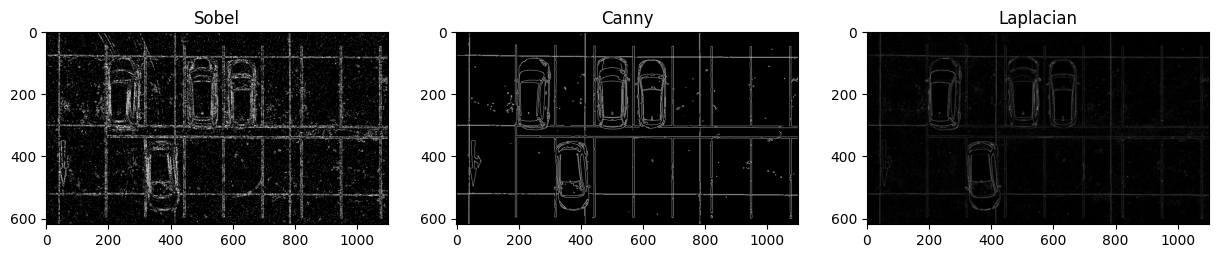

In [17]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/car-park.jpg',0)

# a. Sobel Edge Detection
sobelx = cv.Sobel(img, cv.CV_64F, 1, 0, ksize=5)
sobely = cv.Sobel(img, cv.CV_64F, 0, 1, ksize=5)
sobel_combined = cv.bitwise_or(np.absolute(sobelx), np.absolute(sobely))

# b. Canny Edge Detection
edges_canny = cv.Canny(img, 100, 200)

# c. Laplacian Edge Detection
laplacian = cv.Laplacian(img, cv.CV_64F)
laplacian_abs = np.absolute(laplacian)

plt.figure(figsize=(15,5))
plt.subplot(131), plt.imshow(sobel_combined, cmap='gray'), plt.title('Sobel')
plt.subplot(132), plt.imshow(edges_canny, cmap='gray'), plt.title('Canny')
plt.subplot(133), plt.imshow(laplacian_abs, cmap='gray'), plt.title('Laplacian')
plt.show()

#5. Corner Detection (Harris & Shi-Tomasi)

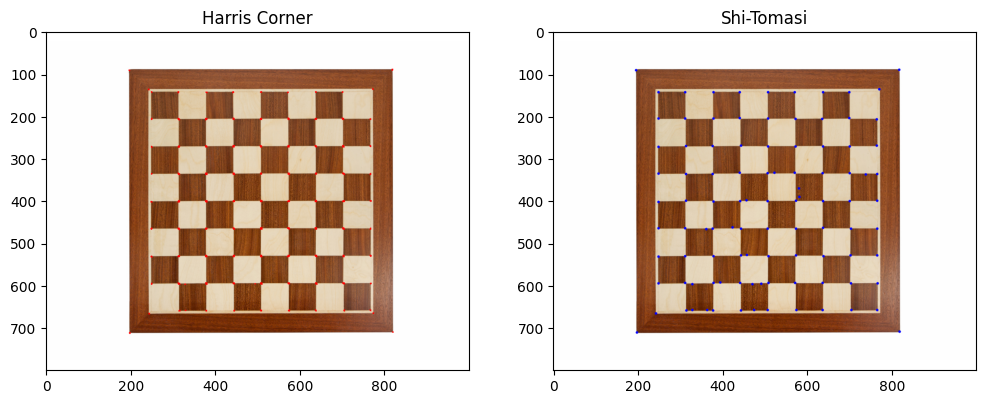

In [20]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/chess-board.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray = np.float32(gray)

# a. Harris Corner Detection
dst = cv.cornerHarris(gray, 2, 3, 0.04)
dst = cv.dilate(dst, None)
img_harris = img.copy()
img_harris[dst > 0.01 * dst.max()] = [0, 0, 255] # Titik merah

# b. Shi-Tomasi Detection
corners = cv.goodFeaturesToTrack(gray, 100, 0.01, 10)
corners = np.intp(corners)
img_shi = img.copy()
for i in corners:
    x, y = i.ravel()
    cv.circle(img_shi, (x, y), 3, 255, -1) # Titik biru

plt.figure(figsize=(12,6))
plt.subplot(121), plt.imshow(cv.cvtColor(img_harris, cv.COLOR_BGR2RGB)), plt.title('Harris Corner')
plt.subplot(122), plt.imshow(cv.cvtColor(img_shi, cv.COLOR_BGR2RGB)), plt.title('Shi-Tomasi')
plt.show()

#6. Hough Transform (Grid Detection - Sudoku)

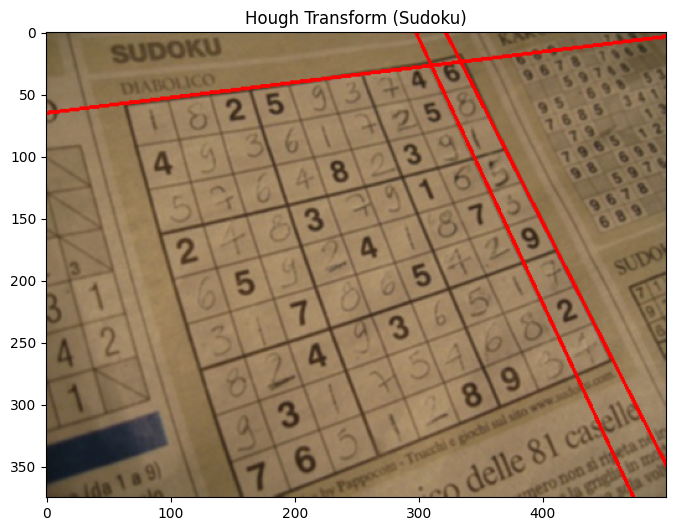

In [22]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/sudoku.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
edges = cv.Canny(gray, 50, 150, apertureSize=3)

lines = cv.HoughLines(edges, 1, np.pi/180, 200)
for line in lines:
    rho, theta = line[0]
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho
    x1 = int(x0 + 1000*(-b))
    y1 = int(y0 + 1000*(a))
    x2 = int(x0 - 1000*(-b))
    y2 = int(y0 - 1000*(a))
    cv.line(img, (x1,y1), (x2,y2), (0,0,255), 2)

plt.figure(figsize=(8,8))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Hough Transform (Sudoku)')
plt.show()

#7. Contour Detection (Laptop)

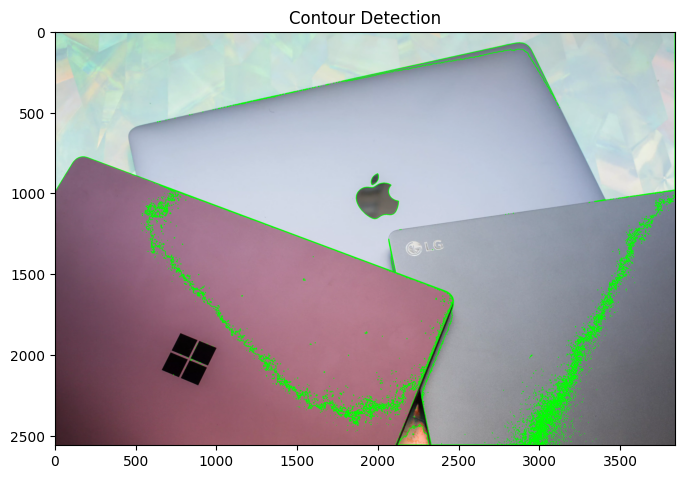

In [23]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/laptop.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
ret, thresh = cv.threshold(img_gray, 127, 255, 0)
contours, hierarchy = cv.findContours(thresh, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)

cv.drawContours(img, contours, -1, (0,255,0), 3)

plt.figure(figsize=(8,8))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Contour Detection')
plt.show()

#D2. Praktikum Feature Matching dan Face Detection
#8. Face Detection (Berbagai Objek)

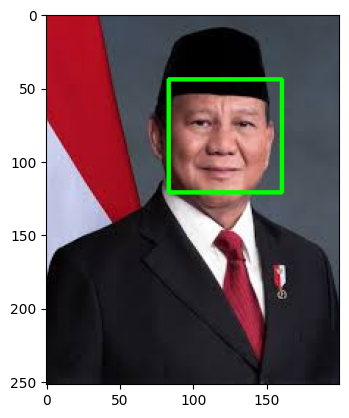

In [26]:
cascade_wajah = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/Images/haarcascades/haarcascade_frontalface_alt.xml')

# Contoh untuk satu gambar (Lakukan iterasi atau copy untuk gambar Kartini/Orang bermasker)
img_face = cv.imread('/content/drive/MyDrive/PCVK/Images/facedet/prabowo.jpg')
gray_face = cv.cvtColor(img_face, cv.COLOR_BGR2GRAY)

roi_wajah = cascade_wajah.detectMultiScale(gray_face, scaleFactor=1.1, minNeighbors=5)
for (x, y, w, h) in roi_wajah:
    cv.rectangle(img_face, (x, y), (x+w, y+h), (0, 255, 0), 2)

plt.imshow(cv.cvtColor(img_face, cv.COLOR_BGR2RGB))
plt.show()

#9. Deteksi Wajah Kucing

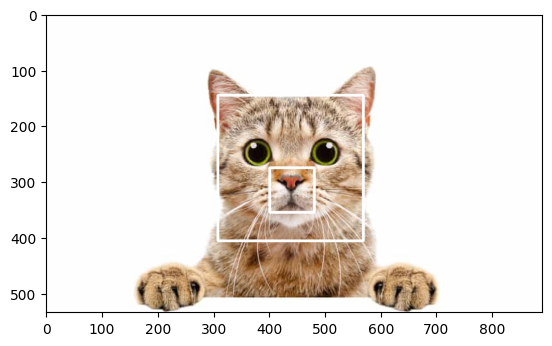

In [28]:
cascade_kucing = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/Images/haarcascades/haarcascade_frontalcatface.xml')
img_cat = cv.imread('/content/drive/MyDrive/PCVK/Images/facedet/kucing.jpg')
gray_cat = cv.cvtColor(img_cat, cv.COLOR_BGR2GRAY)

roi_kucing = cascade_kucing.detectMultiScale(gray_cat, 1.1, 3)
for (x,y,w,h) in roi_kucing:
    cv.rectangle(img_cat, (x,y), (x+w, y+h), (255,255,255), 3)

plt.imshow(cv.cvtColor(img_cat, cv.COLOR_BGR2RGB))
plt.show()

#10 & 11. Deteksi Mata & Senyum

In [29]:
cascade_mata = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/Images/haarcascades/haarcascade_eye.xml')
cascade_senyum = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/Images/haarcascades/haarcascade_smile.xml')

# (Implementasikan menggunakan logika loop .detectMultiScale yang sama seperti wajah)

#13. Blurring Wajah

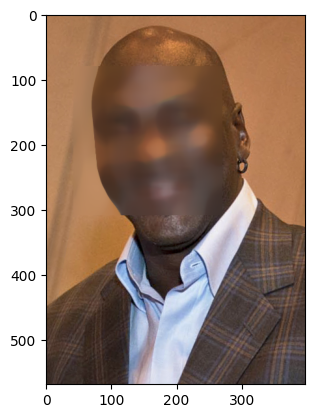

In [31]:
img_blur = cv.imread('/content/drive/MyDrive/PCVK/Images/facedet/mjordan.jpg')
gray_blur = cv.cvtColor(img_blur, cv.COLOR_BGR2GRAY)
roi_wajah = cascade_wajah.detectMultiScale(gray_blur, 1.1, 5)

for (x, y, w, h) in roi_wajah:
    roi = img_blur[y:y+h, x:x+w]
    roi_blurred = cv.medianBlur(roi, 35) # Gunakan cv.medianBlur
    img_blur[y:y+h, x:x+w] = roi_blurred

plt.imshow(cv.cvtColor(img_blur, cv.COLOR_BGR2RGB))
plt.show()

#14. Pengolahan KTM (Feature Matching)

Ukuran gambar KTM (tinggi, lebar): (1014, 1600)


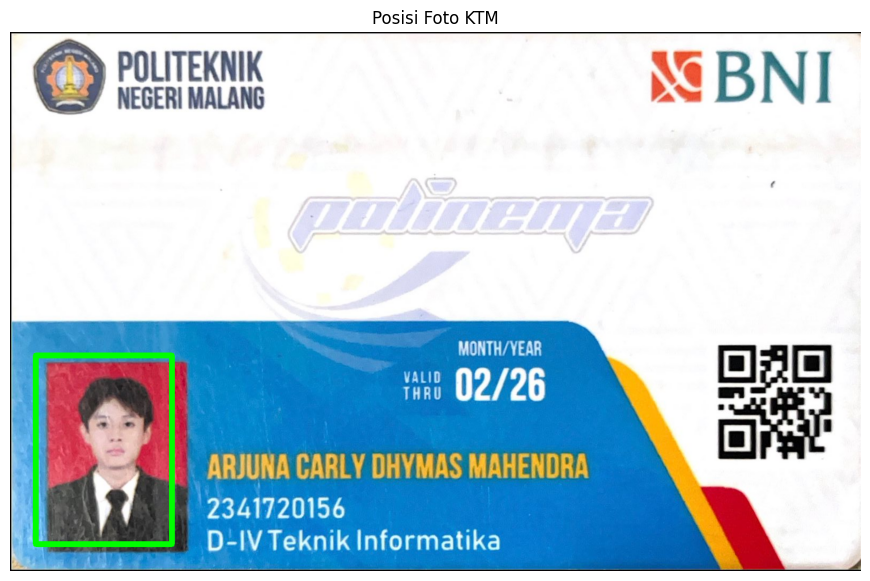

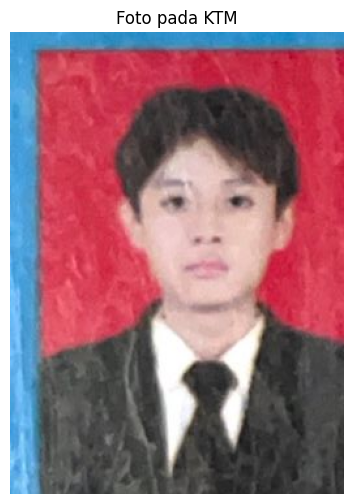

Ukuran foto KTM: (355, 256)


In [43]:
import cv2
import matplotlib.pyplot as plt

ktm_path = '/content/drive/MyDrive/PCVK/Images/ktm.jpeg'

# Membaca gambar KTM
ktm_color = cv2.imread(ktm_path, cv2.IMREAD_COLOR)

if ktm_color is None:
    raise FileNotFoundError("Gambar KTM tidak ditemukan!")

# a. Mendapatkan ukuran gambar
height, width = ktm_color.shape[:2]

print('Ukuran gambar KTM (tinggi, lebar):', (height, width))

# b. Menentukan koordinat foto KTM
# Koordinat menggunakan persentase ukuran gambar
x1 = int(0.03 * width)
y1 = int(0.60 * height)
x2 = int(0.19 * width)
y2 = int(0.95 * height)

PHOTO_BOX = (x1, y1, x2, y2)

# Membuat kotak penanda posisi foto
ktm_preview = ktm_color.copy()

cv2.rectangle(
    ktm_preview,
    (x1, y1),
    (x2, y2),
    (0, 255, 0),
    10
)

# Menampilkan posisi kotak foto
plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(ktm_preview, cv2.COLOR_BGR2RGB))
plt.title('Posisi Foto KTM')
plt.axis('off')
plt.show()

# Melakukan cropping foto KTM
ktm_photo = ktm_color[y1:y2, x1:x2]

# Menampilkan hasil cropping
plt.figure(figsize=(5, 6))
plt.imshow(cv2.cvtColor(ktm_photo, cv2.COLOR_BGR2RGB))
plt.title('Foto pada KTM')
plt.axis('off')
plt.show()

print('Ukuran foto KTM:', ktm_photo.shape[:2])

#D3. Tugas Pengayaan (Pengenalan Karakter KTM dengan CNN)
#A. Persiapan Dataset / Training Data

In [36]:
import os
import cv2
import random
import numpy as np
import pickle
from tqdm import tqdm

DATADIR = "/content/drive/MyDrive/PCVK/Images/dataset/testing"
width, height = 100, 100
dirs = sorted(os.listdir(DATADIR))
training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)
    for img in tqdm(os.listdir(path), desc=char_name):
        try:
            img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
            new_array = cv2.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)
X, Y = [], []
for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X, open("X.pickle", "wb"))
pickle.dump(Y, open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("jumlah data :", len(training_data))
print("jumlah kelas:", len(dirs), dirs)

car1: 100%|██████████| 10/10 [00:04<00:00,  2.30it/s]

jumlah data : 10
jumlah kelas: 1 ['car1']


#B. Membangun & Latih Model CNN

In [37]:
import pickle
from keras.layers import (Input, Conv2D, MaxPooling2D, Flatten, Dense, ZeroPadding2D)
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))
Y = to_categorical(Y)
X = X / 255.0
width, height = 100, 100
jumlah_kelas = Y.shape[1]

inputs = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64, activation='relu')(fc_layer)
outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
model.save('anpr.keras')
print("akurasi training:", riwayat.history['accuracy'][-1])
print("akurasi validasi:", riwayat.history['val_accuracy'][-1])

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis -1 of a tensor of shape (None, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/losses/losses.py:33: SyntaxWarning: In loss categorical_crossentropy, expected y_pred.shape to be (batch_size, num_classes) with num_classes > 1. Received: y_pred.shape=(None, 1). Consider using 'binary_crossentropy' if you only have 2 classes.
  return self.fn(y_true, y_pred, **self._fn_kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 989ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 742ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 8/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 653ms/step - accuracy: 1.0000 - loss: 0.0000e+00 

#C. Testing Data Prediksi Karakter

In [38]:
import os
import cv2
import pickle
import numpy as np
import tensorflow as tf

data_dir_testing = "/content/drive/MyDrive/PCVK/Images/dataset/training"
width, height = 100, 100
model = tf.keras.models.load_model("anpr.keras")
dirs = pickle.load(open("kelas.pickle", "rb"))

for car in sorted(os.listdir(data_dir_testing)):
    temp = ""
    folder = os.path.join(data_dir_testing, car)
    for char_img in sorted(os.listdir(folder)):
        img_array = cv2.imread(os.path.join(folder, char_img), cv2.IMREAD_GRAYSCALE)
        new_array = cv2.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0
        prediction = model.predict(new_array, verbose=0)
        temp += dirs[np.argmax(prediction[0])]
    print("folder name: {} no: {}".format(car, temp))

/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis -1 of a tensor of shape (1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


folder name: 0 no: car1car1car1car1car1
folder name: 1 no: car1car1car1car1car1
folder name: 2 no: car1car1car1car1car1
folder name: 3 no: car1car1car1car1car1
folder name: 4 no: car1car1car1car1car1
folder name: 5 no: car1car1car1car1car1
folder name: 6 no: car1car1car1car1car1
folder name: 7 no: car1car1car1car1car1
folder name: 8 no: car1car1car1car1car1
folder name: 9 no: car1car1car1car1car1
